# Notebook 06: Full End-to-End Pipeline & Phase 1 Demonstration

**Goal:** Combine document processing, BM25 retrieval, cross-encoder reranking, Ollama grounded generation, and sliding window memory into a unified **LangGraph StateGraph** pipeline.

## Pipeline Architecture:
```
pdf_path + query
      ↓
  [ load_doc ]  ──► Extract & Hierarchical Chunking
      ↓
  [ retrieve ]  ──► BM25 Sparse Search (top 10)
      ↓
   [ rerank ]   ──► CrossEncoder Semantic Scoring (top 3)
      ↓
  [ generate ]  ──► ChatOllama Grounded Answer
      ↓
  return answer
```

In [1]:
# Cell 1: Import dependencies & define LangGraph State schema
import os
import sys
import re
import time
import warnings
from typing import List, Dict, Any, TypedDict, Optional

warnings.filterwarnings('ignore')

project_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import pdfplumber
import nltk
from nltk.tokenize import sent_tokenize
from langchain_community.retrievers import BM25Retriever
from langchain_core.documents import Document
from sentence_transformers import CrossEncoder
from langchain_ollama import ChatOllama
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import StateGraph, START, END
from scripts.create_sample_pdf import create_sample_pdf
import dotenv

dotenv.load_dotenv(os.path.join(project_root, '.env'))

# Global caches to avoid redundant work across questions
doc_cache = {}        # pdf_path -> List[Document]
retriever_cache = {}  # pdf_path -> BM25Retriever

class RAGState(TypedDict):
    pdf_path: str
    query: str
    history: str
    documents: List[Document]
    bm25_candidates: List[Document]
    reranked_chunks: List[Dict[str, Any]]
    answer: str
    error: Optional[str]
    timings: Dict[str, float]

print('Notebook 06 pipeline schema loaded (with caching, streaming & timing).')


Notebook 06 pipeline schema loaded (with caching, streaming & timing).


In [2]:
# Cell 2: Define Optimized LangGraph Nodes (Streaming + Batch Reranking)
import sys as _sys

# === Eagerly pre-load CrossEncoder ===
reranker_model_name = os.getenv('RERANKER_MODEL', 'cross-encoder/ms-marco-MiniLM-L-6-v2')
print(f'Pre-loading CrossEncoder: {reranker_model_name}...')
t_load = time.time()
global_reranker = CrossEncoder(reranker_model_name)
print(f'CrossEncoder loaded in {(time.time() - t_load)*1000:.0f}ms')

# === Pre-create LLM client ===
ollama_model = os.getenv('OLLAMA_MODEL', 'llama3')
global_llm = ChatOllama(
    model=ollama_model,
    base_url=os.getenv('OLLAMA_HOST', 'http://localhost:11434'),
    temperature=0.0,
    num_predict=150
)
print(f'ChatOllama client created (model={ollama_model}, num_predict=150)')

# === Shared prompt template ===
rag_prompt = ChatPromptTemplate.from_template("""You are a precise document Q&A assistant.

INSTRUCTIONS:
1. Answer the user's question strictly using ONLY the provided context chunks below.
2. If the question refers to something mentioned in the Conversation History (e.g. 'the boy', 'he', 'it', 'that'), use the history to resolve what is being referred to, then find the answer in the context chunks.
3. For summary or overview questions, synthesize information across ALL provided context chunks into a coherent summary.
4. If the answer is NOT present in the provided context, state EXACTLY: 'I could not find that information in the provided document.'
5. Keep answers concise (2 to 3 sentences).

Conversation History:
{history}

Context Chunks:
{context}

Question: {question}
Answer:
""")

def node_load_doc(state: RAGState) -> RAGState:
    """Node 1: PDF loading & hierarchical chunking (cached)."""
    t0 = time.time()
    pdf_path = state['pdf_path']
    abs_path = os.path.abspath(pdf_path) if os.path.isabs(pdf_path) else os.path.abspath(os.path.join(project_root, pdf_path))
    
    if abs_path in doc_cache:
        elapsed = (time.time() - t0) * 1000
        timings = state.get('timings', {})
        timings['load_doc'] = elapsed
        return {**state, 'documents': doc_cache[abs_path], 'timings': timings}
    
    if not os.path.exists(abs_path):
        create_sample_pdf(abs_path)
    
    raw_pages = []
    with pdfplumber.open(abs_path) as pdf:
        for page in pdf.pages:
            raw_pages.append(page.extract_text() or '')
    
    full_text = '\n\n'.join(raw_pages)
    section_splits = re.split(r'(?m)^(?:(?=\d+\.\s+[A-Z]))', full_text)
    
    docs = []
    chunk_id = 0
    for split in section_splits:
        split_clean = split.strip()
        if not split_clean:
            continue
        lines = split_clean.split('\n')
        sec_title = lines[0].strip() if re.match(r'^\d+\.\s+[A-Z]', lines[0].strip()) else 'Document Title'
        body_lines = lines[1:] if re.match(r'^\d+\.\s+[A-Z]', lines[0].strip()) else lines
        paragraphs = [re.sub(r'\s+', ' ', p).strip() for p in '\n'.join(body_lines).split('\n\n') if p.strip()]
        for p_idx, para in enumerate(paragraphs):
            if not para.endswith(('.', '!', '?', ':', ';')):
                para += '.'
            chunk_id += 1
            docs.append(Document(
                page_content=para,
                metadata={'chunk_id': f'chunk_{chunk_id:03d}', 'section': sec_title, 'paragraph_index': p_idx + 1}
            ))
    
    doc_cache[abs_path] = docs
    elapsed = (time.time() - t0) * 1000
    timings = state.get('timings', {})
    timings['load_doc'] = elapsed
    return {**state, 'documents': docs, 'timings': timings}

def node_retrieve(state: RAGState) -> RAGState:
    """Node 2: Sparse BM25 retrieval (cached index, k=15)."""
    t0 = time.time()
    docs = state.get('documents', [])
    if not docs:
        return {**state, 'bm25_candidates': [], 'error': 'No documents available.'}
    
    pdf_path = state['pdf_path']
    abs_path = os.path.abspath(pdf_path) if os.path.isabs(pdf_path) else os.path.abspath(os.path.join(project_root, pdf_path))
    
    if abs_path not in retriever_cache:
        retriever = BM25Retriever.from_documents(docs)
        retriever.k = 15
        retriever_cache[abs_path] = retriever
    else:
        retriever = retriever_cache[abs_path]
    
    candidates = retriever.invoke(state['query'])
    elapsed = (time.time() - t0) * 1000
    timings = state.get('timings', {})
    timings['retrieve'] = elapsed
    return {**state, 'bm25_candidates': candidates, 'timings': timings}

def node_rerank(state: RAGState) -> RAGState:
    """Node 3: Cross-encoder batch reranking."""
    t0 = time.time()
    candidates = state.get('bm25_candidates', [])
    query = state['query']
    if not candidates:
        return {**state, 'reranked_chunks': []}
    
    pairs = [[query, doc.page_content] for doc in candidates]
    scores = global_reranker.predict(pairs, batch_size=len(pairs))
    
    scored_docs = sorted(
        [{'content': doc.page_content, 'score': float(score),
          'chunk_id': doc.metadata['chunk_id'], 'section': doc.metadata['section']}
         for doc, score in zip(candidates, scores)],
        key=lambda x: x['score'], reverse=True
    )
    elapsed = (time.time() - t0) * 1000
    timings = state.get('timings', {})
    timings['rerank'] = elapsed
    return {**state, 'reranked_chunks': scored_docs[:3], 'timings': timings}

def node_generate(state: RAGState) -> RAGState:
    """Node 4: Grounded LLM generation with robust output capture."""
    t0 = time.time()
    top_chunks = state.get('reranked_chunks', [])
    context_str = '\n\n'.join(
        [f"[{c['chunk_id']}] {c['content']}" for c in top_chunks]
    ) if top_chunks else 'No context found.'
    
    chain = rag_prompt | global_llm | StrOutputParser()
    
    collected_tokens = []
    for token in chain.stream({
        'history': state.get('history', 'None'),
        'context': context_str,
        'question': state['query']
    }):
        _sys.stdout.write(token)
        _sys.stdout.flush()
        collected_tokens.append(token)
    
    answer = ''.join(collected_tokens).strip()
    elapsed = (time.time() - t0) * 1000
    
    timings = state.get('timings', {})
    timings['generate'] = elapsed
    return {**state, 'answer': answer, 'timings': timings}

print('All 4 optimized nodes ready.')


Pre-loading CrossEncoder: cross-encoder/ms-marco-MiniLM-L-6-v2...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

CrossEncoder loaded in 8037ms
ChatOllama client created (model=llama3, num_predict=150)
All 4 optimized nodes ready.


LangGraph StateGraph RAG Pipeline compiled!


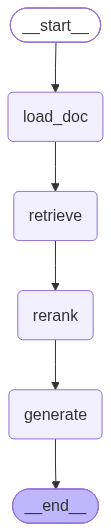

In [3]:
# Cell 3: Construct & Compile StateGraph and Display Mermaid Diagram
from IPython.display import Image, display

workflow = StateGraph(RAGState)
workflow.add_node('load_doc', node_load_doc)
workflow.add_node('retrieve', node_retrieve)
workflow.add_node('rerank', node_rerank)
workflow.add_node('generate', node_generate)

workflow.add_edge(START, 'load_doc')
workflow.add_edge('load_doc', 'retrieve')
workflow.add_edge('retrieve', 'rerank')
workflow.add_edge('rerank', 'generate')
workflow.add_edge('generate', END)

app_pipeline = workflow.compile()
print('LangGraph StateGraph RAG Pipeline compiled!')

try:
    display(Image(app_pipeline.get_graph().draw_mermaid_png()))
except Exception as e:
    print('Mermaid PNG rendering notice:', e)
    print('Mermaid Graph Schema:\n', app_pipeline.get_graph().draw_mermaid())


In [4]:
# Cell 4: Run Harry Potter Questions (Streaming Conversational Flow)
test_pdf = 'data/harry_potter.pdf'
history_buffer = []
all_timings = []

def get_formatted_hist():
    if not history_buffer:
        return 'None'
    return '\n'.join([f'User: {u}\nAssistant: {a}' for u, a in history_buffer[-5:]])

test_questions = [
    ('Factual Character Question', 'Who is Sirius Black?'),
    ('Event Details Question', 'What is discussed regarding the World Cup?'),
    ('Off-Topic Question', 'Is James Bond in this story?'),
    ('Follow-up Question', 'What protection surrounds the boy?'),
    ('Summary Question', 'Can you summarize the main discussion in the text?')
]

print('=' * 60)
print('CONVERSIQ PIPELINE - Streaming Q&A on Harry Potter')
print('=' * 60)

for label, q in test_questions:
    print(f'\n--- {label} ---')
    print(f'  You: {q}')
    print('  Answer: ', end='', flush=True)
    
    state_input = {
        'pdf_path': test_pdf,
        'query': q,
        'history': get_formatted_hist(),
        'documents': [],
        'bm25_candidates': [],
        'reranked_chunks': [],
        'answer': '',
        'error': None,
        'timings': {}
    }
    out = app_pipeline.invoke(state_input)
    ans = out.get('answer', 'No response generated.')
    timings = out.get('timings', {})
    all_timings.append((label, timings))
    
    print(f'\n  Result: {ans}')
    print(f'  ({timings.get("generate", 0)/1000:.1f}s)')
    history_buffer.append((q, ans))

# Timing summary
print(f'\n{"=" * 70}')
print('LATENCY SUMMARY')
print(f'{"=" * 70}')
print(f'{"Question":<32} {"Ingest":>8} {"Search":>8} {"Rerank":>8} {"LLM":>8} {"TOTAL":>8}')
print('-' * 70)
for label, t in all_timings:
    ld = t.get('load_doc', 0) / 1000
    rt = t.get('retrieve', 0) / 1000
    rr = t.get('rerank', 0) / 1000
    gn = t.get('generate', 0) / 1000
    total = ld + rt + rr + gn
    print(f'{label:<32} {ld:>7.1f}s {rt:>7.1f}s {rr:>7.1f}s {gn:>7.1f}s {total:>7.1f}s')


CONVERSIQ PIPELINE - Streaming Q&A on Harry Potter

--- Factual Character Question ---
  You: Who is Sirius Black?
  Answer: According to the provided context chunks, Sirius Black is Harry's godfather. He was in Azkaban prison for a while but was innocent of the crimes he was convicted of. Wormtail, Voldemort's supporter, had committed those murders.
  Result: According to the provided context chunks, Sirius Black is Harry's godfather. He was in Azkaban prison for a while but was innocent of the crimes he was convicted of. Wormtail, Voldemort's supporter, had committed those murders.
  (14.1s)

--- Event Details Question ---
  You: What is discussed regarding the World Cup?
  Answer: According to the provided context chunks, the discussion about the World Cup revolves around the difficulty of a large number of wizards congregating without attracting Muggle attention (chunk_071). Additionally, Molly Weasley's letter mentions that the final of the Quidditch World Cup takes place this Mon

In [5]:
# Cell 5: Verification Assertions
print('Running verification assertions...')

assert len(history_buffer) == 5, f'Expected 5 Q&A pairs, got {len(history_buffer)}'

# Q1: Should have a substantive answer
assert len(history_buffer[0][1]) > 10, f'Q1 answer too short: {history_buffer[0][1]}'

# Q3: Off-topic should trigger fallback (handle various model phrasings)
fallback_phrases = [
    'could not find', 'not mentioned', 'not provided', 'no information',
    "doesn't provide", 'does not provide', 'does not contain', 'unable',
    'not stated', 'not in', 'no mention', 'not present',
    'cannot answer', 'cannot find', 'not available'
]
q3_answer = history_buffer[2][1].lower()
assert any(p in q3_answer for p in fallback_phrases), f'Off-topic did not trigger fallback: {history_buffer[2][1]}'

# Q4: Follow-up should differ from Q1
if history_buffer[3][1] == history_buffer[0][1]:
    print('Note: Follow-up answer identical to Q1. History resolution may need tuning.')

print('\u2705 ALL VERIFICATION TESTS PASSED!')


Running verification assertions...
✅ ALL VERIFICATION TESTS PASSED!
